<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_G02_STRUCTURAL_GEOLOGY_EXPERIMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS G02 — geological fault evidence: displacement, truncation and structural continuity

**Question (falsifiable).** Does label-free *structural* evidence — apparent offset of fabric across a line, termination of persistent ridges at a line, multiscale ridge continuity, lineament-network geometry and competing geological explanations — add equal-area fault proximity beyond G01 wavelet evidence and a simple magnetic gradient, **consistently across held-out geographic folds and discovery splits**?

| ID | candidate | physical idea | judged by |
|---|---|---|---|
| B0 | simple magnetic gradient (THDR) | contrast | — |
| B1 | best G01 magnetic-only map (nested choice) | multiscale magnetic energy | B1 vs B0 |
| B2 | best G01 fusion map (nested choice among G01-C/D/E/F) | joint mag + grav evidence | B2 vs B1, B0 |
| G02-A | displacement | fabric continues across the line but **offset** (step, not oblique slope) | standalone + G01 + G02-A vs G01 |
| G02-B | truncation | persistent ridges **end** along a common line | idem |
| G02-C | continuity | ridge position / strike stable across scales, straight, continuous | idem |
| G02-D | network | segment length, straightness, continuation (colinear / stepover), not forced connectivity | idem |
| G02-E | hypotheses | fault vs contact vs intrusive vs ambiguous support | idem |
| G02-F | G01 + selected G02 evidence (nested choice of base, family, weight) | complementarity | G02-F vs B2 |

**Rules of this notebook**
* Read-only on M9 and G01: cached layers are reused by name; no M9 section is run, no checkpoint touched, no G01 run modified (G01 maps are recomputed by G01's own code inside G02).
* Every G02 map is label-free. Labels are used only to evaluate and — nested, on *other* zones, excluding overlapping ones — to choose B1 / B2 / G02-F variants. No weight or threshold is fitted on a held-out zone.
* `FAST_RESEARCH` is exploratory (2 units per task, 2 wavelengths): it can never yield KEEP. Only `FULL_EVALUATION` gives recommendations.
* Apparent displacement ≠ geological slip. Hypothesis maps are scores, not probabilities.
* **No number exists until the cells run.**

Code: `gems_bench/m9/research/` · configuration: `configs/m9/g02_structural_geology.yaml` · guide: `docs/m9/G02_STRUCTURAL_GEOLOGY.md` · G01 review: `docs/m9/G01_REVIEW_AND_REUSE.md`.

## 0. Configuration, Drive and context

Same workflow as the G01 / M9 notebooks: mount Drive, install the repository at `CONFIG['ref']`, open the pipeline context (data stages validated / staged from Drive, never regenerated) and create the `m9` object **without running any M9 section**.

Prerequisite: M9 section 03 (`s03_spectral`) and, for G01-F, section 02 have run once, so `cache/m9/layers` (on Drive) holds the log-Gabor and cross-modal layers. If not, run the G01 notebook once with `build_missing = {'wavelets': True, 'crossmodal': True}`.

Set `G02_CONFIG['mode']`: start with `FAST_RESEARCH` (minutes per unit), then `FULL_EVALUATION` (all zones, all cached wavelengths, 500 bootstrap draws).

In [ ]:
CONFIG = {                                         # master-pipeline context (data stages are only validated / staged)
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'gems3-discovery-research',               # branch or commit SHA
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',
    'run_mode': 'PREPARE_DATA',
    'failure_policy': 'interactive',
    'download_missing': False,
    'run_advanced_models': False, 'train_baselines': [], 'run_full_inference': False, 'run_submission': False,
    'feature_stage': 'lazy',
    'use_gpu': False,                                # G02 is CPU only
    'seed': 2026,
}
DEM_CONFIG = {'enabled': False, 'mode': 'inventory_only', 'download': False}
PRIVATE_REPO = False

M9_CONFIG = {'profile': 'PILOT', 'overwrite_existing': False}   # only opens the M9 context; no section is run

G02_CONFIG = {
    'mode': 'FAST_RESEARCH',                         # FAST_RESEARCH (exploratory) | FULL_EVALUATION
    'overwrite': False,                              # True rewrites files inside the SAME fingerprinted run folder
    'g01': {'review_run': 'auto'},                   # persisted G01 run to review: auto (LATEST) | none | 'g01_<id>'
    'evaluation': {'tasks': ['geo', 'disc_official']},
    'baselines': {'m9_prediction_npy': None},        # optional: path to an EXISTING full-grid M9 prediction (.npy)
    'save': {'push_to_drive': True, 'keep_tmp': False},
}
SHOW_FIGURES = True

In [10]:
import base64, os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = f"https://github.com/{CONFIG['repo']}.git"

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    tok = userdata.get('GITHUB_TOKEN') or ''
    hdr = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {hdr}'}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args[:3])} failed:\n{r.stderr.strip()[-1500:]}")
    return r

if not os.path.exists(f'{CODE}/.git'):
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'remote', 'set-url', 'origin', REPO_URL)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
before = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if git('-C', CODE, 'rev-parse', '--verify', '-q', f'refs/remotes/origin/{ref}', check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', ref)
    git('-C', CODE, 'merge', '-q', '--ff-only', f'origin/{ref}')
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD
print('code @', HEAD)
if 'gems_bench' in sys.modules and HEAD != before:
    raise RuntimeError('Code changed after gems_bench was imported: Runtime -> Restart session, then run from the top.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
code @ a0f5ffbe33455624496248c2dc1464121d666cb3


In [11]:
import json, pathlib
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from gems_bench.pipeline import Pipeline
from gems_bench.m9.research import G02Experiment

pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG)
pipe.step('bootstrap')
for s in ('raw_data', 'native_grid', 'spatial_folds', 'discovery_splits', 'feature_store'):
    pipe.step(s)                                     # validated on Drive and staged locally (never regenerated)

m9 = pipe.m9(M9_CONFIG)                              # context only: no M9 section, no model, no training
g02 = G02Experiment(m9, G02_CONFIG)                  # constructing it computes nothing
print('mode:', g02.cfg['mode'])

def show(names):
    if not SHOW_FIGURES:
        return
    for n in names:
        p = g02.store.root / 'figures' / f'{n}.png'
        display(Image(filename=str(p))) if p.exists() else print('not produced:', n)

def tab(name, n=40, query=None):
    t = g02.store.load_table(name, 'tables')
    if query and len(t):
        t = t.query(query)
    display(t.head(n)) if len(t) else print('empty / not produced:', name)
    return t

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
[raw_data] SKIP_CACHED: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']
[sync in] 0 copied (0.0 MiB), 1 unchanged, 0s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_grid: ok (1 checks)
[native_grid] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/native_grid.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/native_band_table.csv']
[sync in] 0 copied (0.0 MiB), 3 u

## 1. Inputs and the G01 review (what G01 actually established)

* **What.** Audit the cached layers (both fields per wavelength), choose the G02 scales, fingerprint every input and open the versioned run folder `…/research/G02_structural_geology/g02_<fp>/` with `config/ processed/ rasters/ lineaments/ tables/ figures/ reports/ manifests/`.
* **G01 review (read-only).** The newest persisted G01 run (or `g01.review_run`) is read and the ten review questions are answered **from its tables** — completed steps, informative wavelengths, gravity vs magnetic, strike gate, persistence, tolerance, vs edge, vs M9 cross-modal, fold consistency, redundancy with the gradient. Absent tables are reported as **ABSENT** and the component as **UNVERIFIED** — nothing is assumed.
* **Read.** `tables/g01_review_questions`, `tables/g01_decision_table`, `reports/G01_REVIEW.md`, `tables/g02_scales` (profile offsets, window lengths, search range and offset resolution per wavelength, in metres).

In [12]:
info = g02.prepare()
print('run:', info['run_id'], '->', g02.store.root)
print('G02 wavelengths:', [w.label for w in info['wavelengths']])
for w in info['warnings']:
    print('WARNING', w)
rev = info['g01_review']
print('persisted G01 run found:', rev['available'])
display(rev['questions'])
display(rev['decision_table'])
tab('g02_scales')

[pipeline] research context without segment attributes (geological_eda / segment_attributes not available yet): segment-stratified metrics are skipped
[sync out] 8 copied (0.0 MiB), 0 unchanged, 0s: ['outputs/m9_geofault_production/gems3_engine/inventory']
      model   status          experiment_id profile  n_disc_maps reasons
P5_B0_gated COMPLETE b0_reference__d54e938a    FULL            3        
  P5_B1_bgw COMPLETE b1_bg_weight__7755635b    FULL            3        
[sync in] 0 copied (0.0 MiB), 68 unchanged, 0s: ['experiments/b0_reference__d54e938a/manifest.json', 'experiments/b0_reference__d54e938a/config.yaml', 'experiments/b0_reference__d54e938a/metrics', 'experiments/b0_reference__d54e938a/reports', 'experiments/b0_reference__d54e938a/predictions/oof.tif', 'experiments/b0_reference__d54e938a/predictions/disc0.tif', 'experiments/b0_reference__d54e938a/predictions/disc1.tif', 'experiments/b0_reference__d54e938a/predictions/disc2.tif', 'experiments/b1_bg_weight__7755635b/manifes

,#,question,answer,source
0,1,Which G01 experiments were actually completed?,ABSENT: no G01 run folder (G01 has never been ...,"processed/done_*.json, tables/units"
1,2,Which wavelengths contributed most to fault lo...,ABSENT,tables/ablations
2,3,Did gravity improve magnetic-only evidence?,ABSENT,G01-C vs G01-A
3,4,Did strike agreement help?,ABSENT,G01-D vs G01-C
4,5,Did multiscale persistence help?,ABSENT,G01-E vs G01-D
5,6,Did spatial tolerance improve alignment?,ABSENT (tolerance ablation not run),tables/ablations
6,7,Did G01 outperform simple magnetic-edge detect...,ABSENT,"G01-A vs edge, G01-E vs edge (bootstrap)"
7,8,Did G01 outperform the M9 cross-modal features?,ABSENT,G01-E / G01-C vs G01-F
8,9,Were improvements consistent across geographic...,ABSENT,hypothesis_contrasts.zone_win_share
9,10,Do candidate maps show plausible geology or me...,ABSENT (no unit rasters); plausibility cannot ...,rasters/units/*.npz rank correlation with edge


,Component,Evidence,Incremental value,Geological interpretation,Keep / Reject / Investigate
0,magnetic wavelet energy,G01-A vs edge: ABSENT,ABSENT,not measured,UNVERIFIED
1,gravity wavelet energy,G01-B vs edge: ABSENT,ABSENT,not measured,UNVERIFIED
2,tolerant magnetic-gravity co-location,G01-C vs G01-A: ABSENT,ABSENT,not measured,UNVERIFIED
3,axial strike compatibility,G01-D vs G01-C: ABSENT,ABSENT,not measured,UNVERIFIED
4,multiscale persistence,G01-E vs G01-D: ABSENT,ABSENT,not measured,UNVERIFIED
5,G01 fusion vs M9 engineered cross-modal,G01-E vs G01-F: ABSENT,ABSENT,not measured,UNVERIFIED
6,G01 simple joint vs M9 engineered cross-modal,G01-C vs G01-F: ABSENT,ABSENT,not measured,UNVERIFIED


,wavelength_km,step_m,h1_m,h2_m,half_length_m,max_offset_m,offset_resolution_m,g01_tolerance_m,band
0,0.8,200.0,400.0,800.0,1200.0,800.0,200.0,200.0,narrow
1,1.6,400.0,800.0,1600.0,2400.0,1200.0,400.0,400.0,broad


,wavelength_km,step_m,h1_m,h2_m,half_length_m,max_offset_m,offset_resolution_m,g01_tolerance_m,band
0,0.8,200.0,400.0,800.0,1200.0,800.0,200.0,200.0,narrow
1,1.6,400.0,800.0,1600.0,2400.0,1200.0,400.0,400.0,broad


In [13]:
# Optional: review ANY G01 run folder (read-only; nothing is written into it)
from gems_bench.m9.research.g01_review import review_g01, g01_run_dirs
from gems_bench.m9.research.geology_io import run_root as g01_root
runs = g01_run_dirs(g01_root(m9, g02.g01cfg))
print('G01 runs:', [r.name for r in runs])
if runs:
    display(Markdown(review_g01(runs[-1])['markdown'][:6000]))

G01 runs: ['g01_fb248daf4f']


# G01 review (generated from persisted G01 results)

Run: `/content/gems_work/outputs/m9_geofault_production/research/G01_wavelet_geology/g01_fb248daf4f`

## Ten review questions

| # | question | answer | source |
|---|---|---|---|
| 1 | Which G01 experiments were actually completed? | steps done: exploratory, figures, inputs, metrics, report, unit_disc_official_0, unit_disc_official_1, unit_disc_official_2, unit_geo_0, unit_geo_1, unit_geo_2; units evaluated: 6; candidates with pooled results: ['G01-A', 'G01-A@0.4km', 'G01-A@0.8km', 'G01-A@1.6km', 'G01-A@3.2km', 'G01-B', 'G01-B@0.4km', 'G01-B@0.8km', 'G01-B@1.6km', 'G01-B@3.2km', 'G01-C', 'G01-C@0.4km', 'G01-C@0.8km', 'G01-C@1.6km', 'G01-C@3.2km', 'G01-C\|tol=0m', 'G01-C\|tol=1600m', 'G01-C\|tol=300m', 'G01-C\|tol=800m', 'G01-D', 'G01-D@0.4km', 'G01-D@0.8km', 'G01-D@1.6km', 'G01-D@3.2km', 'G01-E', 'edge', 'random'] | processed/done_*.json, tables/units |
| 2 | Which wavelengths contributed most to fault localisation? | disc_official/G01-A: 0.4km=0.106, 0.8km=0.104, 1.6km=0.097, 3.2km=0.090, 0.8km=0.063, 0.4km=0.060, 1.6km=0.059, 3.2km=0.054, 0.8km=0.042, 1.6km=0.041, 0.4km=0.040, 3.2km=0.038, 1.6km=0.031, 0.8km=0.031, 3.2km=0.029, 0.4km=0.028, 1.6km=0.021, 0.8km=0.020, 3.2km=0.019, 0.4km=0.018, 1.6km=0.008, 0.8km=0.008, 3.2km=0.008, 0.4km=0.007 \| disc_official/G01-B: 0.4km=0.167, 0.8km=0.162, 1.6km=0.140, 3.2km=0.104, 0.4km=0.100, 0.8km=0.096, 1.6km=0.085, 3.2km=0.065, 0.4km=0.064, 0.8km=0.063, 1.6km=0.059, 3.2km=0.046, 0.8km=0.045, 1.6km=0.044, 0.4km=0.044, 3.2km=0.035, 1.6km=0.030, 0.8km=0.029, 0.4km=0.027, 3.2km=0.024, 1.6km=0.012, 0.8km=0.011, 0.4km=0.010, 3.2km=0.010 \| disc_official/G01-C: 0.4km=0.127, 0.8km=0.122, 1.6km=0.113, 3.2km=0.097, 0.4km=0.071, 0.8km=0.068, 1.6km=0.068, 3.2km=0.061, 1.6km=0.048, 0.4km=0.046, 0.8km=0.045, 3.2km=0.044, 1.6km=0.036, 3.2km=0.033, 0.8km=0.032, 0.4km=0.032, 1.6km=0.024, 3.2km=0.023, 0.8km=0.021, 0.4km=0.020, 1.6km=0.010, 3.2km=0.009, 0.8km=0.008, 0.4km=0.007 \| disc_official/G01-D: 0.4km=0.131, 0.8km=0.123, 1.6km=0.117, 3.2km=0.098, 0.4km=0.075, 1.6km=0.071, 0.8km=0.069, 3.2km=0.059, 1.6km=0.049, 0.4km=0.047, 0.8km=0.045, 3.2km=0.043, 1.6km=0.037, 3.2km=0.034, 0.4km=0.033, 0.8km=0.032, 1.6km=0.025, 3.2km=0.023, 0.8km=0.021, 0.4km=0.020, 1.6km=0.010, 3.2km=0.009, 0.8km=0.008, 0.4km=0.007 \| geo/G01-A: 0.4km=0.218, 0.8km=0.193, 1.6km=0.166, 3.2km=0.142, 0.4km=0.119, 0.8km=0.110, 1.6km=0.105, 3.2km=0.095, 0.4km=0.077, 1.6km=0.076, 0.8km=0.073, 3.2km=0.073, 1.6km=0.060, 3.2km=0.059, 0.8km=0.055, 0.4km=0.055, 3.2km=0.045, 1.6km=0.044, 0.8km=0.037, 0.4km=0.036, 3.2km=0.022, 1.6km=0.021, 0.8km=0.016, 0.4km=0.015 \| geo/G01-B: 0.4km=0.338, 0.8km=0.282, 1.6km=0.214, 0.4km=0.194, 0.8km=0.161, 3.2km=0.151, 1.6km=0.129, 0.4km=0.125, 0.8km=0.107, 3.2km=0.101, 1.6km=0.093, 0.4km=0.088, 0.8km=0.080, 3.2km=0.079, 1.6km=0.073, 3.2km=0.066, 0.4km=0.057, 0.8km=0.056, 1.6km=0.054, 3.2km=0.051, 1.6km=0.026, 3.2km=0.025, 0.8km=0.025, 0.4km=0.024 \| geo/G01-C: 0.4km=0.259, 0.8km=0.213, 1.6km=0.181, 3.2km=0.147, 0.4km=0.147, 0.8km=0.119, 1.6km=0.109, 3.2km=0.095, 0.4km=0.093, 0.8km=0.079, 1.6km=0.078, 3.2km=0.073, 0.4km=0.065, 1.6km=0.062, 3.2km=0.060, 0.8km=0.059, 1.6km=0.046, 3.2km=0.045, 0.4km=0.042, 0.8km=0.041, 1.6km=0.022, 3.2km=0.022, 0.8km=0.019, 0.4km=0.017 \| geo/G01-D: 0.4km=0.274, 0.8km=0.222, 1.6km=0.189, 0.4km=0.152, 3.2km=0.146, 0.8km=0.124, 1.6km=0.113, 0.4km=0.095, 3.2km=0.092, 0.8km=0.082, 1.6km=0.081, 3.2km=0.069, 0.4km=0.067, 1.6km=0.063, 0.8km=0.060, 3.2km=0.056, 1.6km=0.046, 3.2km=0.042, 0.4km=0.042, 0.8km=0.041, 1.6km=0.022, 3.2km=0.021, 0.8km=0.018, 0.4km=0.017 \|\| nested choices: {('G01-A:wavelength', 'G01-A@0.4km'): 2, ('G01-A:wavelength', 'G01-A@0.8km'): 1, ('G01-A:wavelength', 'G01-A@1.6km'): 1, ('G01-A:wavelength', 'G01-A@3.2km'): 2, ('G01-B:wavelength', 'G01-B@0.4km'): 5, ('G01-B:wavelength', 'G01-B@0.8km'): 1, ('G01-C:tolerance', 'G01-C\|tol=0m'): 4, ('G01-C:tolerance', 'G01-C\|tol=1600m'): 2, ('G01-C:wavelength', 'G01-C@0.4km'): 3, ('G01-C:wavelength', 'G01-C@1.6km'): 2, ('G01-C:wavelength', 'G01-C@3.2km'): 1, ('G01-D:wavelength', 'G01-D@0.4km'): 3, ('G01-D:wavelength', 'G01-D@1.6km'): 2, ('G01-D:wavelength', 'G01-D@3.2km'): 1} | tables/ablations, nested_choice |
| 3 | Did gravity improve magnetic-only evidence? | disc_official: delta=+0.0028, P(>0)=0.63, zones won=0.67 INCONCLUSIVE; geo: delta=+0.0030, P(>0)=0.63, zones won=0.33 INCONCLUSIVE | G01-C vs G01-A |
| 4 | Did strike agreement help? | disc_official: delta=+0.0016, P(>0)=0.86, zones won=1.00 INCONCLUSIVE; geo: delta=-0.0004, P(>0)=0.44, zones won=0.33 INCONCLUSIVE | G01-D vs G01-C |
| 5 | Did multiscale persistence help? | disc_official: delta=+0.0002, P(>0)=0.61, zones won=0.67 INCONCLUSIVE; geo: delta=+0.0056, P(>0)=1.00, zones won=1.00 SUPPORTED | G01-E vs G01-D |
| 6 | Did spatial tolerance improve alignment? | disc_official:0m=0.116 \| disc_official:300m=0.116 \| disc_official:800m=0.115 \| disc_official:1600m=0.115 \| disc_official:0m=0.068 \| disc_official:300m=0.067 \| disc_official:800m=0.067 \| disc_official:1600m=0.066 \| disc_official:0m=0.045 \| disc_official:1600m=0.045 \| disc_official:300m=0.044 \| disc_official:800m=0.044 \| disc_official:1600m=0.033 \| disc_official:0m=0.033 \| disc_official:300m=0.033 \| disc_official:800m=0.032 \| disc_official:1600m=0.021 \| disc_official:800m=0.021 \| disc_official:300m=0.021 \| disc_official:0m=0.021 \| disc_official:1600m=0.008 \| disc_official:800m=0.008 \| disc_official:0m=0.008 \| disc_official:300m=0.008 \| geo:0m=0.204 \| geo:300m=0.202 \| geo:800m=0.197 \| geo:1600m=0.194 \| geo:0m=0.120 \| geo:300m=0.119 \| geo:800m=0.117 \| geo:1600m=0.115 \| geo:0m=0.084 \| geo:300m=0.083 \| geo:1600m=0.082 \| geo:800m=0.082 \| geo:0m=0.064 \| geo:300m=0.064 \| geo:1600m=0.063 \| geo:800m=0.063 \| geo:1600m=0.045 \| geo:0m=0.045 \| geo:300m=0.045 \| geo:800m=0.045 \| geo:1600m=0.021 \| geo:800m=0.021 \| geo:300m=0.021 \| geo:0m=0.021 | tables/ablations (G01-C\|tol=...) |
| 7

## 2. Held-out evaluation (tiled, resumable)

Per unit (geographic fold `geo`, discovery split `disc_official`):
1. Percentile references on the unit's **training geography** (`assert_disjoint` raises on any overlap with the evaluation zone).
2. Tiles (`tiling.tile_px`) with a halo computed from the scales → G01 maps (B0, G01-A..F, per-wavelength variants, M, G, J, P) and G02-A / B / C / E, written into memory-mapped arrays under `processed/tmp_<unit>/` (resumable per tile).
3. G02-D networks on the unit window from each `network.sources` evidence map → `lineaments/<unit>_<source>.geojson` (+ `.gpkg`), segment / node tables.
4. Equal-area counts per 20 km block for every candidate (seeded tie-break noise shared by all maps), complementarity, truth-length strata, label-free rank correlations, wavelength usage, lineament-geometry metrics, official-style DTI.
5. One streamed NPZ per unit `rasters/units/<unit>.npz` (float16 maps + domain + interior; labels never stored).

**Resume.** `processed/done_unit_*.json` per unit; an interrupted unit resumes at the next tile while its `tmp_` folder survives (local disk).

In [14]:
units = g02.evaluate()
display(units)

[g02] geo_0: reused
[g02] geo_1: reused
[g02] disc_official_0: reused
[g02] disc_official_1: reused
[sync out] 173 copied (1664.7 MiB), 0 unchanged, 35s: ['outputs/m9_geofault_production/research/G02_structural_geology/g02_23686a63cb']


,unit,task,zone,status,eval_px,eligible_px,domain_px,truth_px,reference_px,block_px,n_candidates,n_maps,networks,seconds,protocol_key
0,geo_0,geo,0,computed,1887813,1886771,1866883,18341,2787669,200,40,90,"{'G01-E': {'n_segments': 3940, 'hi': 0.7335031...",1255.7,b205c189d912f6d6
1,geo_1,geo,1,computed,1548292,1548011,1534542,21795,3266483,200,40,90,"{'G01-E': {'n_segments': 1908, 'hi': 0.8733583...",485.9,b25ca968e42356b6
2,disc_official_0,disc_official,0,computed,1784107,1766770,1758260,7542,3381745,200,40,90,"{'G01-E': {'n_segments': 5392, 'hi': 0.8169396...",1563.1,5320855164c2bc4a
3,disc_official_1,disc_official,1,computed,1848909,1833733,1821324,7452,3316943,200,40,90,"{'G01-E': {'n_segments': 5439, 'hi': 0.8127560...",1698.1,2f6b1f343577d8c0


## 3. Metrics, nested choices, contrasts, recommendations

* **Nested virtual candidates.** B1, B2, `F:<base>+<family>` (weight chosen) and G02-F (base, family and weight chosen) are picked for each held-out zone on the task's *other* zones, excluding zones whose evaluation footprint overlaps (`tables/unit_overlap`). Choices: `tables/nested_choices`.
* **Contrasts** (`tables/contrasts`, metric `decision.metric`; `tables/contrasts_precision` for false-positive reduction): paired spatial-block bootstrap at the primary budget / distance; SUPPORTED = Δ > 0, P(Δ > 0) ≥ 0.9 and ≥ 67 % of zones won; REFUTED = Δ < 0 and P(Δ > 0) ≤ 0.1.
  * `standalone`: family vs B0, random, B2 · `incremental`: base + family vs base (**the decision criterion**) · `field`: magnetic vs gravity · `band`: narrow vs broad · `network`: network on G01 evidence vs on the edge · `fusion`: G02-F vs B2.
* **Recommendations** (`tables/recommendations`): KEEP / INVESTIGATE / REJECT / UNVERIFIED from the incremental contrasts only (KEEP needs SUPPORTED on `disc_official` and no REFUTED elsewhere, in FULL_EVALUATION with ≥ 3 zones).
* **Complementarity** (`tables/complement_pooled`): truth missed by B0 (or a G01 base) and recovered by a candidate, relative to random at the same budget; precision of the candidate's new picks.
* **Geometry** (`tables/lineament_metrics`): segment-length precision, truth recall and orientation agreement at length budgets — separate from pixel ranking.

In [15]:
res = g02.metrics()
display(res['recommendations'])
cols = ['family', 'kind', 'task', 'candidate', 'reference', 'delta', 'ci_lo', 'ci_hi', 'p_delta_positive',
        'zone_win_share', 'n_zones', 'verdict']
H = res['contrasts']
display(H[[c for c in cols if c in H]])
f0, d0 = g02.cfg['evaluation']['primary_area_frac'], g02.cfg['evaluation']['primary_distance_m']
P = res['pooled']
heads = ['B0', 'B1', 'B2', 'G02-A', 'G02-B', 'G02-C', 'G02-D', 'G02-E', 'G02-F', 'random']
display(P[(P.area_frac == f0) & (P.tol_m == d0) & P.candidate.isin(heads)]
        [['task', 'candidate', 'precision', 'recall', 'f1', 'enrichment', 'precision_vs_edge']])
display(res['complement'])
display(res['lineament'])

[sync out] 2 copied (0.1 MiB), 171 unchanged, 2s: ['outputs/m9_geofault_production/research/G02_structural_geology/g02_23686a63cb']


,family,recommendation,provisional,mode,best_delta,best_p_delta_positive,best_reference,best_task,notes
0,G02-A,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.021378,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
1,G02-B,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,-0.014237,0.08,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
2,G02-C,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.032354,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
3,G02-D,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.012630,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
4,G02-E,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.012489,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
5,G02-F,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.038457,1.00,B2,geo,0 held-out zones on disc_official (< 3); FAST_...


,family,kind,task,candidate,reference,delta,ci_lo,ci_hi,p_delta_positive,zone_win_share,n_zones,verdict
0,baseline,baseline,disc_official,B1,B0,NaN,NaN,NaN,NaN,NaN,0,INCONCLUSIVE
1,baseline,baseline,geo,B1,B0,-0.029746,-0.043144,-0.018337,0.00,0.0,2,REFUTED
2,baseline,baseline,disc_official,B2,B1,NaN,NaN,NaN,NaN,NaN,0,INCONCLUSIVE
3,baseline,baseline,geo,B2,B1,0.015642,-0.008212,0.040398,0.84,1.0,2,INCONCLUSIVE
4,baseline,baseline,disc_official,B2,B0,NaN,NaN,NaN,NaN,NaN,0,INCONCLUSIVE
...,...,...,...,...,...,...,...,...,...,...,...,...
63,G02-D,network,geo,G02-D,net[edge],0.002554,-0.021106,0.025094,0.56,1.0,2,INCONCLUSIVE
64,G02-F,fusion,disc_official,G02-F,B2,NaN,NaN,NaN,NaN,NaN,0,INCONCLUSIVE
65,G02-F,fusion,geo,G02-F,B2,0.038457,0.023523,0.049643,1.00,1.0,2,SUPPORTED
66,G02-F,fusion,disc_official,G02-F,B0,NaN,NaN,NaN,NaN,NaN,0,INCONCLUSIVE


,task,candidate,precision,recall,f1,enrichment,precision_vs_edge
4,disc_official,B0,0.033626,0.077431,0.046889,1.108129,1.000000
145,disc_official,G02-A,0.039353,0.163599,0.063444,1.296858,1.170313
160,disc_official,G02-B,0.028569,0.071228,0.040781,0.941496,0.849626
175,disc_official,G02-C,0.042528,0.199947,0.070138,1.401503,1.264747
190,disc_official,G02-D,0.036661,0.079498,0.050181,1.208171,1.090280
199,disc_official,G02-E,0.038794,0.140456,0.060796,1.278446,1.153697
220,disc_official,random,0.030152,0.578898,0.057319,0.993665,0.896705
229,geo,B0,0.110807,0.089147,0.098804,1.313227,1.000000
238,geo,B1,0.082662,0.059298,0.069058,0.979665,0.745998
247,geo,B2,0.109671,0.068990,0.084699,1.299755,0.989741


,task,reference,candidate,n_missed_by_ref,n_recovered,n_new_picks,n_new_hits,recovered_share,new_pick_precision,random_recovered_share,random_new_pick_precision,recovery_vs_random
0,disc_official,G01-E,G01-A,13926,500,73096,2033,0.035904,0.027813,0.574680,0.029280,0.062477
1,disc_official,G01-E,G02-A,13926,1835,76152,2713,0.131768,0.035626,0.574680,0.029280,0.229289
2,disc_official,G01-E,G02-B,13926,1004,102402,2888,0.072095,0.028203,0.574680,0.029280,0.125453
3,disc_official,G01-E,G02-C,13926,2439,84736,3573,0.175140,0.042166,0.574680,0.029280,0.304761
4,disc_official,G01-E,G02-D,13926,474,34043,1260,0.034037,0.037012,0.574680,0.029280,0.059228
5,disc_official,G01-E,G02-E,13926,1474,66901,2545,0.105845,0.038041,0.574680,0.029280,0.184181
6,disc_official,G01-E,random,13926,8003,101263,2965,0.574680,0.029280,0.574680,0.029280,1.000000
7,disc_official,edge,G01-A,13833,142,4409,138,0.010265,0.031300,0.580568,0.029748,0.017681
8,disc_official,edge,G01-E,13833,712,61656,2390,0.051471,0.038763,0.580568,0.029748,0.088656
9,disc_official,edge,G02-A,13833,2043,84946,3346,0.147690,0.039390,0.580568,0.029748,0.254389


,task,source,network,budget_km_per_100km2,tol_m,length_precision,truth_recall,random_precision,orientation_agreement
0,disc_official,G01-E,G02-D,5.0,0.0,0.005631,0.001935,0.004190,0.659233
1,disc_official,G01-E,G02-D,5.0,300.0,0.033347,0.011996,0.030354,0.592060
2,disc_official,G01-E,G02-D,5.0,1000.0,0.097909,0.047217,0.088510,0.611466
3,disc_official,G01-E,G02-D,10.0,0.0,0.006069,0.004269,0.004190,0.673801
4,disc_official,G01-E,G02-D,10.0,300.0,0.035864,0.027010,0.030354,0.609058
5,disc_official,G01-E,G02-D,10.0,1000.0,0.097202,0.094853,0.088510,0.622365
6,disc_official,G01-E,G02-D,20.0,0.0,0.005110,0.007263,0.004190,0.609376
7,disc_official,G01-E,G02-D,20.0,300.0,0.037124,0.061468,0.030354,0.578414
8,disc_official,G01-E,G02-D,20.0,1000.0,0.101751,0.163447,0.088510,0.603219
9,disc_official,edge,net[edge],5.0,0.0,0.009709,0.003809,0.004190,0.857852


## 4. Figures (16:9, PNG + PDF + plotted data CSV in `figures/`)

Maps use one 50 km window centred on the held-out truth of the evaluated unit with the most truth (UTM 11N km; red = held-out truth, black = known faults: **evaluation figures**, labels never enter a map). Examples are seeded picks that include **strong and weak** evidence and strong gradients without G02 evidence.

1 raw fields + faults · 2 wavelet energy by scale · 3 orientation / coherence / discordance · 4 cross-fault profiles · 5 displacement examples · 6 truncation examples · 7 ridge continuity · 8 multiscale persistence · 9 candidate network · 10 G01 vs G02 maps · 11 TP / FP / missed case studies · 12 performance vs distance · 13 performance vs area · 14 per-fold improvements · 15 geological explanations + uncertainty.

In [17]:
import inspect
import numpy as np

# Inspect the variables used in figures()
print("G02 module:", inspect.getfile(type(g02)))

# Patch the affected source file
from pathlib import Path

path = Path("/content/GEMS/gems_bench/m9/research/g02_experiment.py")
source = path.read_text()

old = "wg = (wl[0] + r0, wl[1] + r0, wl[2] + c0, wl[3] + c0)"

new = """wg = (
                wl[0] + int(r0),
                wl[1] + int(r0),
                wl[2] + int(c0),
                wl[3] + int(c0),
            )"""

assert source.count(old) == 1, "Expected exactly one matching line"
path.write_text(source.replace(old, new))

print("Patch applied:", path)

G02 module: /content/GEMS/gems_bench/m9/research/g02_experiment.py
Patch applied: /content/GEMS/gems_bench/m9/research/g02_experiment.py


TypeError: unsupported operand type(s) for +: 'int' and 'str'

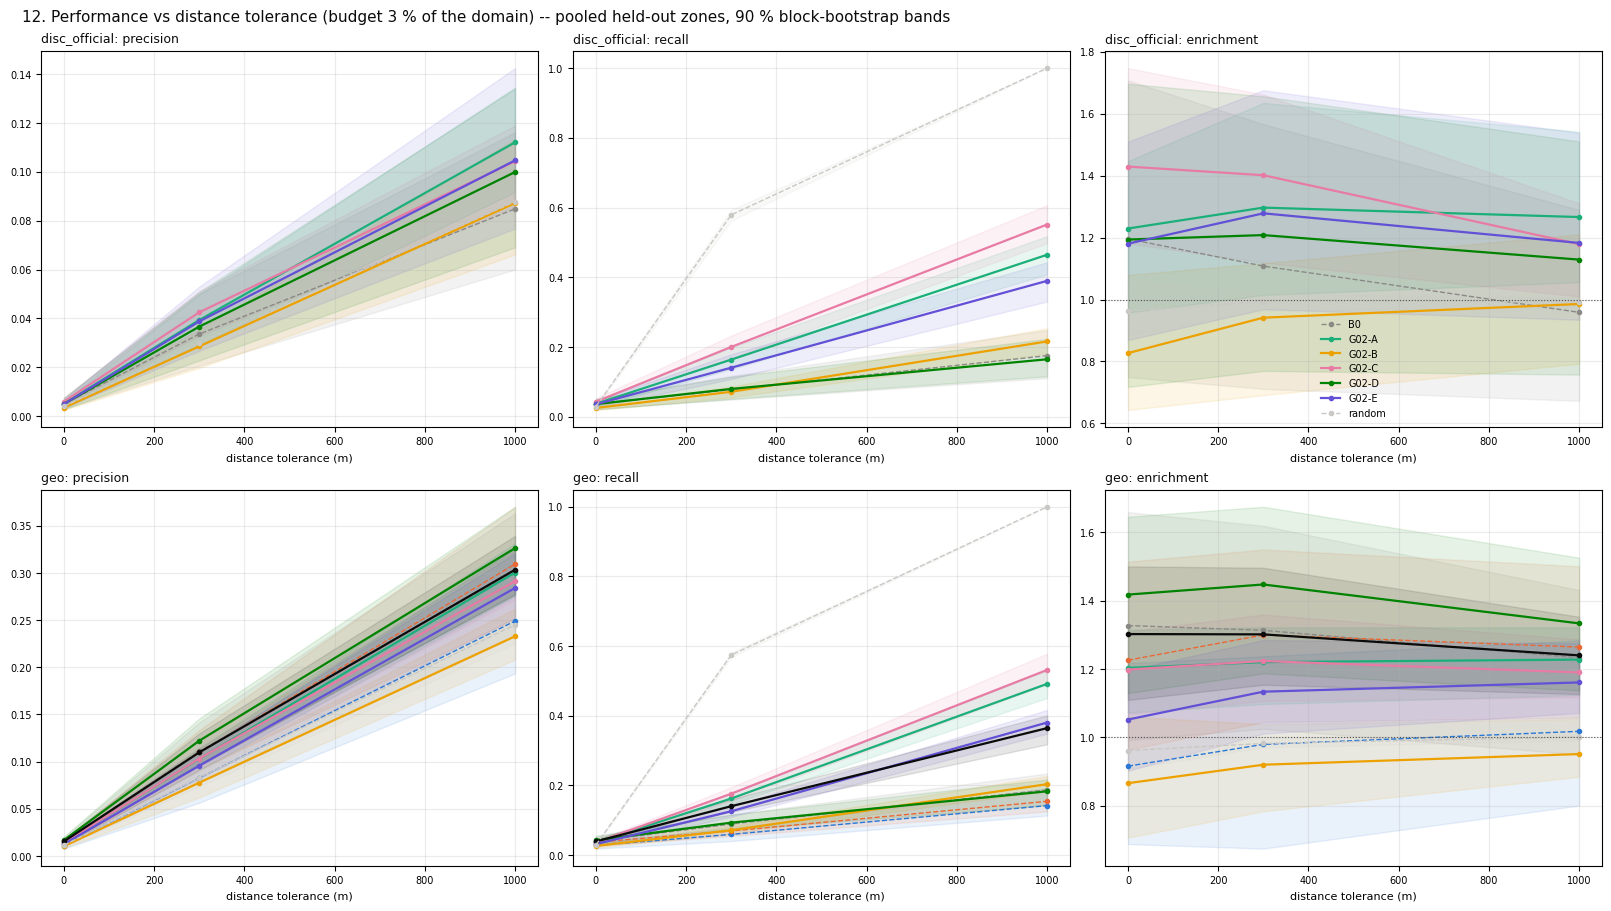

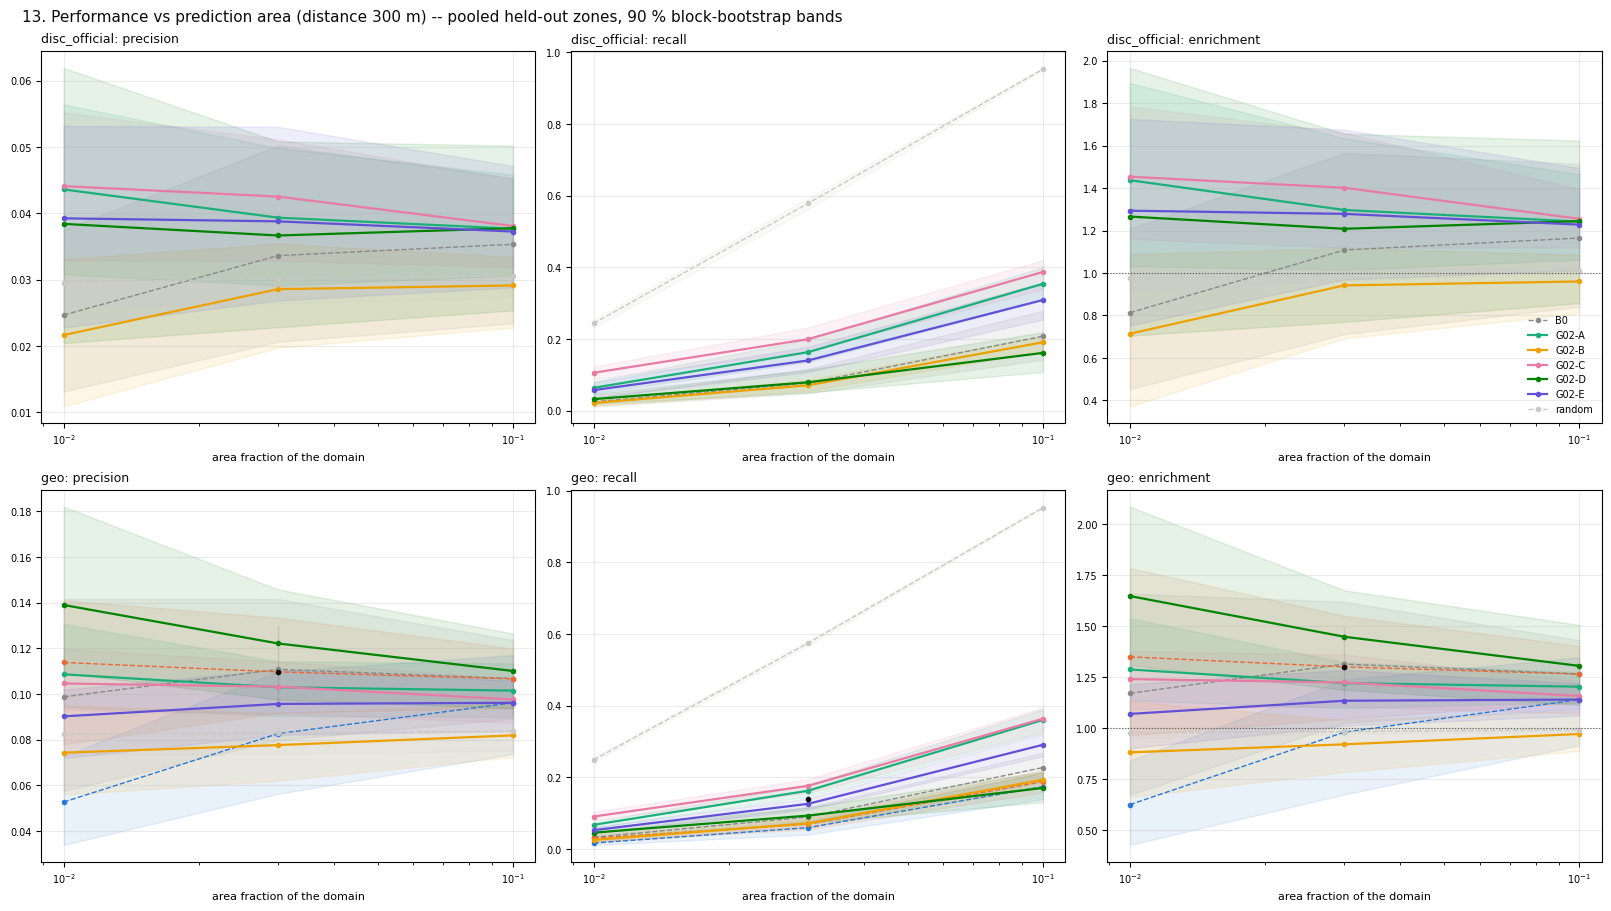

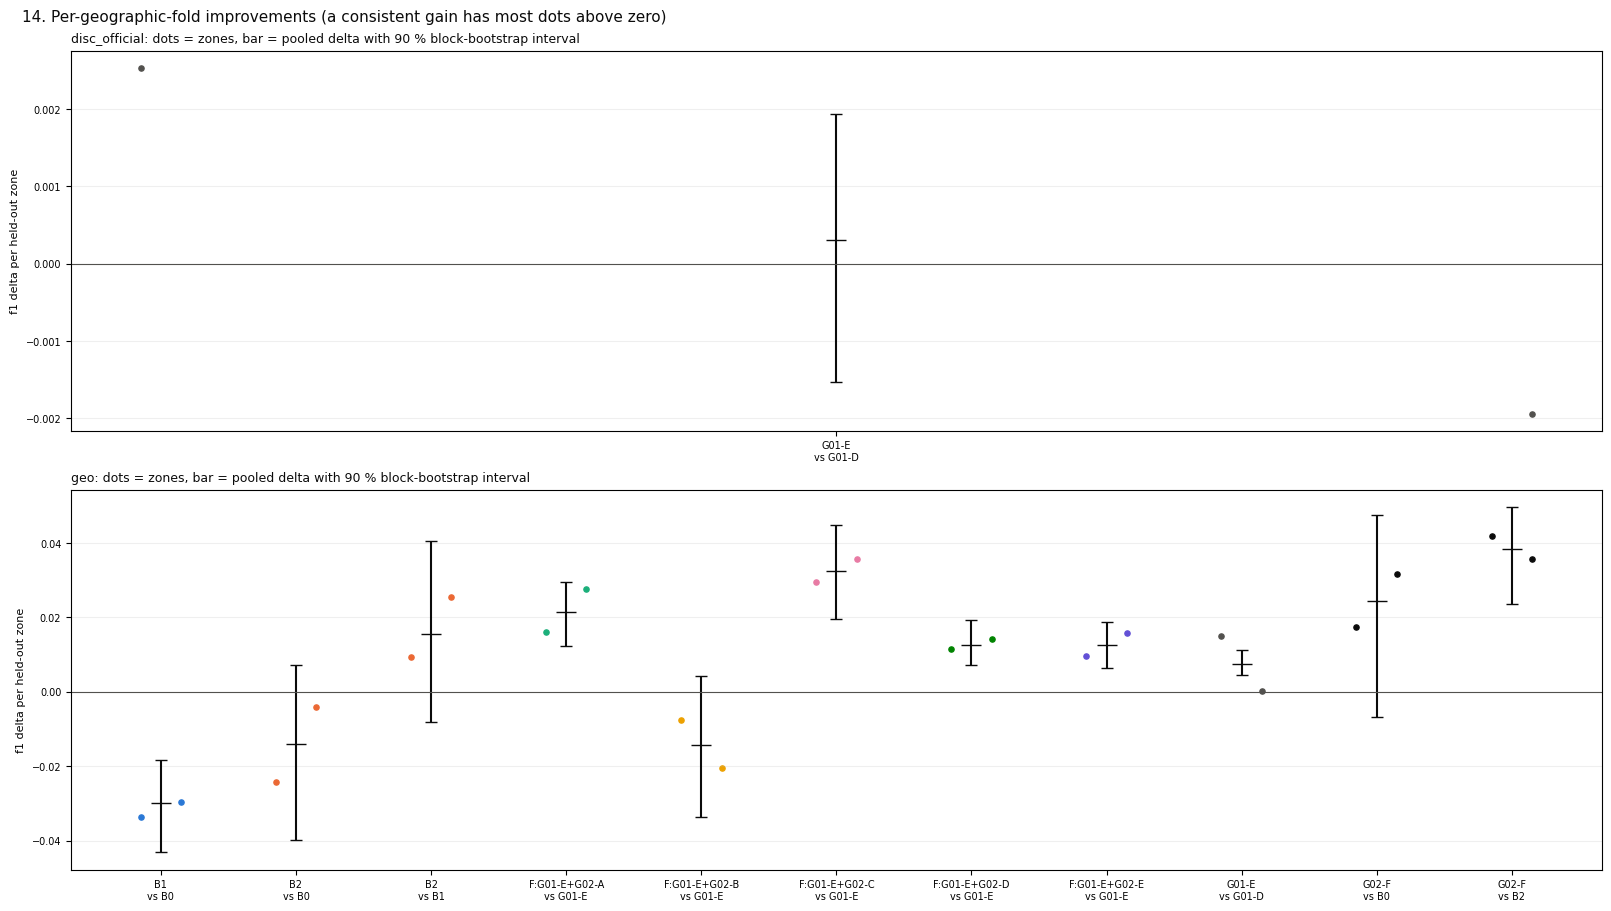

In [18]:
written = g02.figures()
show(['01_raw_fields_faults', '02_wavelet_energy', '03_orientation_coherence', '04_cross_fault_profiles',
      '05_displacement_examples', '06_truncation_examples', '07_ridge_continuity', '08_multiscale_persistence',
      '09_candidate_network', '10_g01_vs_g02', '11_case_studies', '12_performance_vs_distance',
      '13_performance_vs_area', '14_per_fold_improvements', '15_geological_explanations'])

## 5. Report and decision

`reports/G02_REPORT.md` is generated from the tables: recommendations, contrasts, pooled results and the nine decision questions (displacement vs gradient misses, truncation independence, persistence, false-positive reduction, wavelengths, magnetic vs gravity, complementarity with M9, regional consistency, integration). Copy the verdicts into `docs/m9/G02_STRUCTURAL_GEOLOGY.md` → *Results* by hand after reading figures 10, 11 and 14.

In [19]:
rep = g02.report()
display(Markdown(rep.read_text()[:12000]))
g02.push()
print('local :', g02.store.root)
print('Drive :', m9.cfg.get('_drive_root'), '/', g02.cfg['output_subdir'], '/', g02.store.root.name)

[sync out] 3 copied (0.1 MiB), 172 unchanged, 0s: ['outputs/m9_geofault_production/research/G02_structural_geology/g02_23686a63cb']


# G02 structural geology: run `g02_23686a63cb` (FAST_RESEARCH)

Generated 2026-10-27 13:57 by `gems_bench.m9.research` (g02.1). Guide: `docs/m9/G02_STRUCTURAL_GEOLOGY.md`. G01 review: `reports/G01_REVIEW.md`.

> Every number below was produced by this run. Evidence maps are hypothesis scores, not calibrated probabilities. The held-out zones were inspected in earlier GEMS work (not an untouched test set). Separate from the official competition score.

> **FAST_RESEARCH: exploratory subset of zones / scales. No recommendation below can be KEEP; run FULL_EVALUATION before any integration decision.**

## Warnings

* G01-F unavailable (no cached m9:xmod:mag_grav_* layer): B2 family reduced
* no persisted G01 run: G01 review is ABSENT (G02 recomputes G01 maps itself)

## Recommendations (from incremental contrasts only)

| family | recommendation | provisional | mode | best_delta | best_p_delta_positive | best_reference | best_task | notes |
|---|---|---|---|---|---|---|---|---|
| G02-A | UNVERIFIED | UNVERIFIED | FAST_RESEARCH | 0.02138 | 1 | G01-E | geo | 0 held-out zones on disc_official (< 3); FAST_RESEARCH: exploratory subset, never a final verdict (provisional: UNVERIFIED) |
| G02-B | UNVERIFIED | UNVERIFIED | FAST_RESEARCH | -0.01424 | 0.08 | G01-E | geo | 0 held-out zones on disc_official (< 3); FAST_RESEARCH: exploratory subset, never a final verdict (provisional: UNVERIFIED) |
| G02-C | UNVERIFIED | UNVERIFIED | FAST_RESEARCH | 0.03235 | 1 | G01-E | geo | 0 held-out zones on disc_official (< 3); FAST_RESEARCH: exploratory subset, never a final verdict (provisional: UNVERIFIED) |
| G02-D | UNVERIFIED | UNVERIFIED | FAST_RESEARCH | 0.01263 | 1 | G01-E | geo | 0 held-out zones on disc_official (< 3); FAST_RESEARCH: exploratory subset, never a final verdict (provisional: UNVERIFIED) |
| G02-E | UNVERIFIED | UNVERIFIED | FAST_RESEARCH | 0.01249 | 1 | G01-E | geo | 0 held-out zones on disc_official (< 3); FAST_RESEARCH: exploratory subset, never a final verdict (provisional: UNVERIFIED) |
| G02-F | UNVERIFIED | UNVERIFIED | FAST_RESEARCH | 0.03846 | 1 | B2 | geo | 0 held-out zones on disc_official (< 3); FAST_RESEARCH: exploratory subset, never a final verdict (provisional: UNVERIFIED) |

## Contrasts (f1, budget 3 %, distance 300 m; paired block bootstrap)

| family | kind | task | candidate | reference | delta | ci_lo | ci_hi | p_delta_positive | zone_win_share | n_zones | verdict |
|---|---|---|---|---|---|---|---|---|---|---|---|
| baseline | baseline | disc_official | B1 | B0 |  |  |  |  |  | 0 | INCONCLUSIVE |
| baseline | baseline | geo | B1 | B0 | -0.02975 | -0.04314 | -0.01834 | 0 | 0 | 2 | REFUTED |
| baseline | baseline | disc_official | B2 | B1 |  |  |  |  |  | 0 | INCONCLUSIVE |
| baseline | baseline | geo | B2 | B1 | 0.01564 | -0.008212 | 0.0404 | 0.84 | 1 | 2 | INCONCLUSIVE |
| baseline | baseline | disc_official | B2 | B0 |  |  |  |  |  | 0 | INCONCLUSIVE |
| baseline | baseline | geo | B2 | B0 | -0.0141 | -0.03975 | 0.007246 | 0.14 | 0 | 2 | INCONCLUSIVE |
| baseline | baseline | disc_official | G01-E | G01-D | 0.0003054 | -0.001524 | 0.001931 | 0.65 | 0.5 | 2 | INCONCLUSIVE |
| baseline | baseline | geo | G01-E | G01-D | 0.007508 | 0.004557 | 0.01118 | 1 | 1 | 2 | SUPPORTED |
| G02-A | standalone | disc_official | G02-A | B0 | 0.01656 | 0.001644 | 0.03158 | 0.95 | 1 | 2 | SUPPORTED |
| G02-A | standalone | geo | G02-A | B0 | 0.02719 | -0.001702 | 0.05204 | 0.94 | 1 | 2 | SUPPORTED |
| G02-A | standalone | disc_official | G02-A | random | 0.006125 | -0.008036 | 0.02128 | 0.7 | 0.5 | 2 | INCONCLUSIVE |
| G02-A | standalone | geo | G02-A | random | -0.01888 | -0.02988 | -0.006199 | 0 | 0 | 2 | REFUTED |
| G02-A | standalone | disc_official | G02-A | B2 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-A | standalone | geo | G02-A | B2 | 0.04129 | 0.02451 | 0.05817 | 1 | 1 | 2 | SUPPORTED |
| G02-A | incremental | disc_official | F:G01-E+G02-A | G01-E |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-A | incremental | geo | F:G01-E+G02-A | G01-E | 0.02138 | 0.01243 | 0.02945 | 1 | 1 | 2 | SUPPORTED |
| G02-B | standalone | disc_official | G02-B | B0 | -0.006108 | -0.02673 | 0.01118 | 0.34 | 0 | 2 | INCONCLUSIVE |
| G02-B | standalone | geo | G02-B | B0 | -0.02456 | -0.06047 | 0.000807 | 0.06 | 0 | 2 | REFUTED |
| G02-B | standalone | disc_official | G02-B | random | -0.01654 | -0.02887 | -0.006039 | 0.01 | 0 | 2 | REFUTED |
| G02-B | standalone | geo | G02-B | random | -0.07062 | -0.0855 | -0.05231 | 0 | 0 | 2 | REFUTED |
| G02-B | standalone | disc_official | G02-B | B2 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-B | standalone | geo | G02-B | B2 | -0.01045 | -0.03151 | 0.009919 | 0.23 | 0.5 | 2 | INCONCLUSIVE |
| G02-B | incremental | disc_official | F:G01-E+G02-B | G01-E |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-B | incremental | geo | F:G01-E+G02-B | G01-E | -0.01424 | -0.03355 | 0.004171 | 0.08 | 0 | 2 | REFUTED |
| G02-C | standalone | disc_official | G02-C | B0 | 0.02325 | 0.004669 | 0.04223 | 0.98 | 1 | 2 | SUPPORTED |
| G02-C | standalone | geo | G02-C | B0 | 0.03134 | -0.004698 | 0.05486 | 0.93 | 1 | 2 | SUPPORTED |
| G02-C | standalone | disc_official | G02-C | random | 0.01282 | 0.003003 | 0.02447 | 1 | 1 | 2 | SUPPORTED |
| G02-C | standalone | geo | G02-C | random | -0.01472 | -0.0297 | 0.0007383 | 0.06 | 0 | 2 | REFUTED |
| G02-C | standalone | disc_official | G02-C | B2 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-C | standalone | geo | G02-C | B2 | 0.04545 | 0.02487 | 0.0632 | 1 | 1 | 2 | SUPPORTED |
| G02-C | incremental | disc_official | F:G01-E+G02-C | G01-E |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-C | incremental | geo | F:G01-E+G02-C | G01-E | 0.03235 | 0.01961 | 0.04467 | 1 | 1 | 2 | SUPPORTED |
| G02-D | standalone | disc_official | G02-D | B0 | 0.003292 | -0.01253 | 0.02325 | 0.65 | 1 | 2 | INCONCLUSIVE |
| G02-D | standalone | geo | G02-D | B0 | 0.006757 | -0.0192 | 0.02886 | 0.68 | 1 | 2 | INCONCLUSIVE |
| G02-D | standalone | disc_official | G02-D | random | -0.007138 | -0.02513 | 0.01255 | 0.28 | 0 | 2 | INCONCLUSIVE |
| G02-D | standalone | geo | G02-D | random | -0.03931 | -0.0629 | -0.0152 | 0 | 0 | 2 | REFUTED |
| G02-D | standalone | disc_official | G02-D | B2 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-D | standalone | geo | G02-D | B2 | 0.02086 | 0.01265 | 0.03325 | 1 | 1 | 2 | SUPPORTED |
| G02-D | incremental | disc_official | F:G01-E+G02-D | G01-E |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-D | incremental | geo | F:G01-E+G02-D | G01-E | 0.01263 | 0.007254 | 0.01938 | 1 | 1 | 2 | SUPPORTED |
| G02-E | standalone | disc_official | G02-E | B0 | 0.01391 | -0.002568 | 0.02741 | 0.92 | 1 | 2 | SUPPORTED |
| G02-E | standalone | geo | G02-E | B0 | 0.00985 | -0.0122 | 0.03119 | 0.78 | 1 | 2 | INCONCLUSIVE |
| G02-E | standalone | disc_official | G02-E | random | 0.003477 | -0.01147 | 0.02279 | 0.55 | 1 | 2 | INCONCLUSIVE |
| G02-E | standalone | geo | G02-E | random | -0.03622 | -0.05073 | -0.02032 | 0 | 0 | 2 | REFUTED |
| G02-E | standalone | disc_official | G02-E | B2 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-E | standalone | geo | G02-E | B2 | 0.02396 | 0.009634 | 0.03879 | 0.98 | 1 | 2 | SUPPORTED |
| G02-E | incremental | disc_official | F:G01-E+G02-E | G01-E |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-E | incremental | geo | F:G01-E+G02-E | G01-E | 0.01249 | 0.006518 | 0.01882 | 1 | 1 | 2 | SUPPORTED |
| G02-A | field | disc_official | G02-A[mag] | random | -0.004193 | -0.01778 | 0.009921 | 0.31 | 0 | 2 | INCONCLUSIVE |
| G02-A | field | geo | G02-A[mag] | random | -0.02544 | -0.04118 | -0.003652 | 0.01 | 0 | 2 | REFUTED |
| G02-A | field | disc_official | G02-A[grav] | random | 0.008686 | -0.003996 | 0.02025 | 0.81 | 0.5 | 2 | INCONCLUSIVE |
| G02-A | field | geo | G02-A[grav] | random | -0.02303 | -0.04238 | -0.009069 | 0.01 | 0 | 2 | REFUTED |
| G02-A | field | disc_official | G02-A | G02-A[mag] | 0.01032 | -0.002361 | 0.02124 | 0.93 | 1 | 2 | SUPPORTED |
| G02-A | field | geo | G02-A | G02-A[mag] | 0.006562 | -0.0108 | 0.02296 | 0.71 | 1 | 2 | INCONCLUSIVE |
| G02-B | field | disc_official | G02-B[mag] | random | -0.03923 | -0.05125 | -0.03108 | 0 | 0 | 2 | REFUTED |
| G02-B | field | geo | G02-B[mag] | random | -0.05752 | -0.07344 | -0.04213 | 0 | 0 | 2 | REFUTED |
| G02-B | field | disc_official | G02-B[grav] | random | -0.007068 | -0.02281 | 0.003706 | 0.21 | 0 | 2 | INCONCLUSIVE |
| G02-B | field | geo | G02-B[grav] | random | -0.06618 | -0.08415 | -0.04904 | 0 | 0 | 2 | REFUTED |
| G02-B | field | disc_official | G02-B | G02-B[mag] | 0.02269 | 0.007785 | 0.03666 | 1 | 1 | 2 | SUPPORTED |
| G02-B | field | geo | G02-B | G02-B[mag] | -0.0131 | -0.02856 | 0.002492 | 0.08 | 0.5 | 2 | REFUTED |
| G02-C | band | disc_official | G02-C[narrow] | G02-C[broad] | 0.00138 | -0.005222 | 0.007264 | 0.56 | 1 | 2 | INCONCLUSIVE |
| G02-C | band | geo | G02-C[narrow] | G02-C[broad] | 0.005557 | -0.002343 | 0.01221 | 0.82 | 0.5 | 2 | INCONCLUSIVE |
| G02-D | network | disc_official | G02-D | net[edge] | -0.01619 | -0.03315 | 0.003077 | 0.09 | 0 | 2 | REFUTED |
| G02-D | network | geo | G02-D | net[edge] | 0.002554 | -0.02111 | 0.02509 | 0.56 | 1 | 2 | INCONCLUSIVE |
| G02-F | fusion | disc_official | G02-F | B2 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-F | fusion | geo | G02-F | B2 | 0.03846 | 0.02352 | 0.04964 | 1 | 1 | 2 | SUPPORTED |
| G02-F | fusion | disc_official | G02-F | B0 |  |  |  |  |  | 0 | INCONCLUSIVE |
| G02-F | fusion | geo | G02-F | B0 | 0.02435 | -0.006659 | 0.0476 | 0.92 | 1 | 2 | SUPPORTED |

## Pooled held-out results

| task | candidate | precision | recall | f1 | enrichment | precision_vs_edge | f1_lo | f1_hi |
|---|---|---|---|---|---|---|---|---|
| disc_official | B0 | 0.03363 | 0.07743 | 0.04689 | 1.108 | 1 | 0.02858 | 0.06944 |
| disc_official | G02-A | 0.03935 | 0.1636 | 0.06344 | 1.297 | 1.17 | 0.04804 | 0.07899 |
| disc_official | G02-B | 0.02857 | 0.07123 | 0.04078 | 0.9415 | 0.8496 | 0.02991 | 0.04989 |
| disc_official | G02-C | 0.04253 | 0.1999 | 0.07014 | 1.402 | 1.265 | 0.05526 | 0.08335 |
| disc_official | G02-D | 0.03666 | 0.0795 | 0.05018 | 1.208 | 1.09 | 0.03222 | 0.06965 |
| disc_official | G02-E | 0.03879 | 0.1405 | 0.0608 | 1.278 | 1.154 | 0.04409 | 0.0805 |
| disc_official | random | 0.03015 | 0.5789 | 0.05732 | 0.9937 | 0.8967 | 0.05046 | 0.06257 |
| geo | B0 | 0.1108 | 0.08915 | 0.0988 | 1.313 | 1 | 0.0692 | 0.121 |
| geo | B1 | 0.08266 | 0.0593 | 0.06906 | 0.9797 | 0.746 | 0.04572 | 0.08975 |
| geo | B2 | 0.1097 | 0.06899 | 0.0847 | 1.3 | 0.9897 | 0.0683 | 0.1056 |
| geo | G02-A | 0.103 | 0.1623 | 0.126 | 1.22 | 0.9292 | 0.1124 | 0.1378 |
| geo | G02-B | 0.07764 | 0.07113 | 0.07425 | 0.9202 | 0.7007 | 0.06332 | 0.08389 |
| geo | G02-C | 0.1032 | 0.1761 | 0.1301 | 1.223 | 0.9315 | 0.1172 | 0.1421 |
| geo | G02-D | 0.1221 | 0.09296 | 0.1056 | 1.447 | 1.102 | 0.08656 | 0.1248 |
| geo | G02-E | 0.09567 | 0.1257 | 0.1087 | 1.134 | 0.8634 | 0.09481 | 0.121 |
| geo | G02-F | 0.1098 | 0.1402 | 0.1232 | 1.301 | 0.991 | 0.1109 | 0.138 |
| geo | random | 0.08289 | 0.5744 | 0.1449 | 0.9823 | 0.748 | 0.1306 | 0.1608 |

## Decision questions (answered from the tables above)

1. **Does displacement find faults missed by gradient detection?** disc_official: recovers 0.148 of truth missed by edge (0.25x random), new-pick precision 0.039; geo: recovers 0.146 of truth missed by edge (0.25x random), new-pick precision 0.104
2. **Does truncation provide independent information?** increment: disc_official: INCONCLUSIVE (delta +nan, P>0 nan); geo: REFUTED (delta -0.0142, P>0 0.08); redundancy with G01-E median Spearman 0.03, with the edge median Spearman 0.02
3. **Does persistence improve reliability?** G01-E vs G01-D: disc_official: INCONCLUSIVE (delta +0.0003, P>0 0.65); geo: SUPPORTED (delta +0.0075, P>0 1.00); G02-C increment: disc_official: INCONCLUSIVE (delta +nan, P>0 nan); geo: SUPPORTED (delta +0.0324, P>0 1.00)
4. **Can geological continuity reduce false positives?** see `contrasts_precision` (precision deltas of the incr

[sync out] 0 copied (0.0 MiB), 175 unchanged, 0s: ['outputs/m9_geofault_production/research/G02_structural_geology/g02_23686a63cb']
local : /content/gems_work/outputs/m9_geofault_production/research/G02_structural_geology/g02_23686a63cb
Drive : /content/drive/MyDrive/GEMS_2/outputs/m9_geofault_production / research/G02_structural_geology / g02_23686a63cb


## 6. Geological interpretation (write after reading the tables, not the maps)

* **G02-A.** Does displacement recover faults the gradient misses (`complement_pooled`, recovery vs random > 1) *and* add over G01 (incremental)? A standalone gain without an increment means it re-finds what G01 already finds.
* **G02-B.** Truncation should be weakly correlated with G01 (`rank_correlations`). High correlation + no increment = it is an energy-edge detector in disguise.
* **G02-C / D.** Do continuity / network raise *precision* (`contrasts_precision`)? A recall-only gain means they spread selections along lineaments rather than removing false positives.
* **G02-E.** Where is `ambiguous` dominant on truth (figure 11, 15)? That is the share of mapped faults the physics here cannot distinguish from other boundaries.
* **Consistency.** A gain carried by one zone (figure 14) is not a gain.
* **Integration.** Only KEEP from FULL_EVALUATION may be proposed for M7 / M9 post-processing — as a separate, pre-registered experiment. Nothing here touches a submission.

## Resume / reload / Drive synchronisation

* **Push.** Every unit, `metrics`, `figures` and `report` push the run folder to Drive (`m9.push`, only `research/G02_structural_geology/<run>`); the cell below pushes again explicitly.
* **Reload after a disconnect.** Run section 0, then either re-run any section (finished units / steps are reused from the fingerprinted folder; `stage_inputs` brings it back from Drive first) or attach and read results only.
* **Switch mode.** `FAST_RESEARCH` and `FULL_EVALUATION` have different fingerprints, hence different folders: they never overwrite each other.

In [20]:
from gems_bench.m9.research.g02_io import list_runs, run_root
display(list_runs(run_root(m9, g02.cfg)))
g02_old = G02Experiment.attach(m9)                  # newest run; or attach(m9, run_id='g02_...')
old = g02_old.results()
display(old['recommendations'])
print(json.dumps(old['summary'], indent=1, default=str)[:3000])
g02_old.push()                                      # explicit Drive sync of that run folder

,run_id,mode,fingerprint,updated,n_artifacts,steps_done
0,g02_23686a63cb,FAST_RESEARCH,23686a63cb148020,2026-10-27T13:57:09,163,"[inputs, metrics, report, unit_disc_official_0..."


[sync in] 6 copied (0.1 MiB), 327 unchanged, 1s: ['cache/m9/layers', 'outputs/m9_geofault_production/research/G01_wavelet_geology', 'outputs/m9_geofault_production/research/G02_structural_geology']


,family,recommendation,provisional,mode,best_delta,best_p_delta_positive,best_reference,best_task,notes
0,G02-A,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.021378,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
1,G02-B,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,-0.014237,0.08,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
2,G02-C,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.032354,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
3,G02-D,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.012630,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
4,G02-E,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.012489,1.00,G01-E,geo,0 held-out zones on disc_official (< 3); FAST_...
5,G02-F,UNVERIFIED,UNVERIFIED,FAST_RESEARCH,0.038457,1.00,B2,geo,0 held-out zones on disc_official (< 3); FAST_...


{
 "run_id": "g02_23686a63cb",
 "fingerprint": "23686a63cb148020",
 "mode": "FAST_RESEARCH",
 "primary_area_frac": 0.03,
 "primary_distance_m": 300.0,
 "decision": {
  "metric": "f1",
  "min_p_positive": 0.9,
  "min_zone_win_share": 0.67,
  "primary_task": "disc_official",
  "min_zones": 3
 },
 "warnings": [
  "G01-F unavailable (no cached m9:xmod:mag_grav_* layer): B2 family reduced",
  "no persisted G01 run: G01 review is ABSENT (G02 recomputes G01 maps itself)"
 ],
 "status": "EXPLORATORY (FAST_RESEARCH subset): not a held-out verdict",
 "pooled": {
  "disc_official": {
   "B0": {
    "precision": 0.033625730994152045,
    "recall": 0.07743097238895558,
    "f1": 0.04688907501935932,
    "enrichment": 1.1081294469298824,
    "precision_vs_edge": 1.0
   },
   "G02-A": {
    "precision": 0.0393526278541364,
    "recall": 0.16359877284247032,
    "f1": 0.06344417040695767,
    "enrichment": 1.2968582228539693,
    "precision_vs_edge": 1.1703129327056216
   },
   "G02-B": {
    "precisi